In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load DataSet

In [64]:
df = pd.read_excel('english_to_urdu_dataset.xlsx')
df = df.iloc[:10000]
df['urdu'] = df['urdu'].fillna('').astype(str).apply(lambda x: '<start>' + x + '<end>')
df.head()

,eng,urdu
0,the book of the generation of jesus christ th...,<start>یسوع مسیح ابن داود ابن ابرہام کا نسب نا...
1,abraham begat isaac and isaac begat jacob an...,<start>ابراہام سے اضحاق پیدا ہوا اور اضحاق سے ...
2,and judas begat phares and zara of thamar and...,<start>اور یہوداہ سے فارص اور زارح تمر سے پیدا...
3,and aram begat aminadab and aminadab begat na...,<start>اور رام سے عمینداب پیدا ہوا اور عمینداب...
4,and salmon begat booz of rachab and booz bega...,<start>اور سلمون سے بوعز راحب سے پیدا ہوا اور ...


### Train Test Split

In [65]:
english_sentence = df['eng'].values
urdu_sentence = df['urdu'].values

In [66]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=True)

### Tokenization

In [67]:
from tensorflow.keras.preprocessing.text import Tokenizer

# English
eng_tokenizer = Tokenizer()
eng_tokenizer.fit_on_texts(english_sentence)
encoder_input = eng_tokenizer.texts_to_sequences(english_sentence)

# Urdu
urd_tokenizer = Tokenizer(filters = '')
urd_tokenizer.fit_on_texts(urdu_sentence)
decoder_input = urd_tokenizer.texts_to_sequences(urdu_sentence)

### Padding

In [68]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
encoder_input = pad_sequences(encoder_input, padding='pre')
decoder_input = pad_sequences(decoder_input, padding='pre')

### Vocabulary Size

In [69]:
eng_vocab_size = len(eng_tokenizer.word_index)+1
urd_vocab_size = len(urd_tokenizer.word_index)+1

print("English : ", eng_vocab_size)
print("Urdu : ", urd_vocab_size)

English :  6561
Urdu :  8770


### Max Length

In [70]:
encoder_max = encoder_input.shape[1]
decoder_max = decoder_input.shape[1]

print("Encoder Max : ", encoder_max)
print("Decoder Max : ", decoder_max)

Encoder Max :  68
Decoder Max :  84


### Target

In [ ]:
decoder_target = np.zeros_like(decoder_input)
decoder_target[:, : -1] = decoder_input[:, 1:]
decoder_target = np.expand_dims(decoder_target, -1)

## Transformer Archeticture

In [72]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, MultiHeadAttention, LayerNormalization, Dense

### Encoder Archeticture

In [73]:
encoder_inputs = Input(shape=(encoder_max, ))
encoder_embedding = Embedding(input_dim=eng_vocab_size, output_dim=128)(encoder_inputs)

### Positional Encoding

In [74]:
positional = tf.range(start=0, limit=encoder_max, delta=1)
positional_embedding = Embedding(input_dim=encoder_max, output_dim=128)(positional)

## Add Encoder Embedding + Positional
x = encoder_embedding + positional_embedding

### Multi-Head Attention

In [75]:
encoder_attention = MultiHeadAttention(num_heads=4, key_dim=128)(x, x)

### Add & Normalize

In [76]:
encoder_add = x + encoder_attention
enocder_norm = LayerNormalization()(encoder_add)

### Feed Forward Network

In [ ]:
encoder_ffn = Dense(128, activation='softmax')(enocder_norm)

### Encoder Output

In [ ]:
encoder_output = Dense(128)(encoder_ffn)

### Decoder Archeticture

In [78]:
decoder_inputs = Input(shape=(decoder_max, ))
decoder_embedding = Embedding(input_dim=urd_vocab_size, output_dim=128)(decoder_inputs)

### Positional

In [79]:
decoder_positional = tf.range(start=0, limit=decoder_max, delta=1)
decoder_positional_embedding = Embedding(input_dim=decoder_max, output_dim=128)(decoder_positional)

# Add Decoder Embedding + Positional
decoder_x = decoder_embedding + decoder_positional_embedding

### Masked Multi-Head Attention

In [80]:
decoder_attention = MultiHeadAttention(num_heads=4, key_dim=128)(decoder_x, decoder_x, use_causal_mask=True)

### Add & Norm

In [81]:
decoder_add = decoder_attention + decoder_x
decoder_norm = LayerNormalization()(decoder_add)

### Cross Attention

In [82]:
cross_attention = MultiHeadAttention(num_heads=8, key_dim=128)(decoder_norm, encoder_output)

### 2nd Add & Norm

In [83]:
decoder_add2 = cross_attention + decoder_norm
decoder_norm2 = LayerNormalization()(decoder_add2)

### Feed Forward Network

In [84]:
decoder_ffn = Dense(512, activation='relu')(decoder_norm2)

# Output
deocoder_output = Dense(128, activation='softmax')(decoder_ffn)

### 3rd Add & Norm

In [85]:
decoder_add3 = deocoder_output + decoder_norm2
decoder_norm3 = LayerNormalization()(decoder_add3)

### Output Layer

In [86]:
output = Dense(urd_vocab_size, activation='softmax')(decoder_norm3)

### Complete Model

In [88]:
model = Model(
    [encoder_inputs, decoder_inputs],
    output
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 68)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, 68, 128)   │    839,808 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_5       │ (None, 84)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 68, 128)   │          0 │ embedding_10[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_12        │ (None, 84, 128)   │  1,122,560 │ input_layer_5[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 68, 128)   │    263,808 │ add_12[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_12[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 84, 128)   │          0 │ embedding_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 68, 128)   │          0 │ add_12[0][0],     │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 84, 128)   │    263,808 │ add_14[0][0],     │
│ (MultiHeadAttentio… │                   │            │ add_14[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 68, 128)   │        256 │ add_13[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 84, 128)   │          0 │ multi_head_atten… │
│                     │                   │            │ add_14[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 68, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 84, 128)   │        256 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 68, 128)   │     16,512 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 84, 128)   │    527,488 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 84, 128)   │          0 │ multi_head_atten… │
│                     │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 84, 128)   │        256 │ add_16[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 84, 512)   │     66,048 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,314,562 (16.46 MB)

 Trainable params: 4,314,562 (16.46 MB)

 Non-trainable params: 0 (0.00 B)

### Model Compilation

In [89]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Model Trining

In [90]:
history = model.fit([encoder_input, decoder_input], decoder_target, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 473s 2s/step - accuracy: 0.9693 - loss: 1.9467 - val_accuracy: 1.0000 - val_loss: 0.0036
Epoch 2/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 399s 2s/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 3/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 1381s 6s/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 7.1272e-04
Epoch 4/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 398s 2s/step - accuracy: 1.0000 - loss: 6.2492e-04 - val_accuracy: 1.0000 - val_loss: 4.1844e-04
Epoch 5/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 364s 2s/step - accuracy: 1.0000 - loss: 3.7519e-04 - val_accuracy: 1.0000 - val_loss: 2.7199e-04
Epoch 6/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 1265s 5s/step - accuracy: 1.0000 - loss: 2.4768e-04 - val_accuracy: 1.0000 - val_loss: 1.8675e-04
Epoch 7/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 403s 2s/step - accuracy: 1.0000 - loss: 1.7161e-04 - val_accuracy: 1.0000 - val_loss: 1.3266e-04
Epoch 8/20
228/228 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accu

### Accuracy

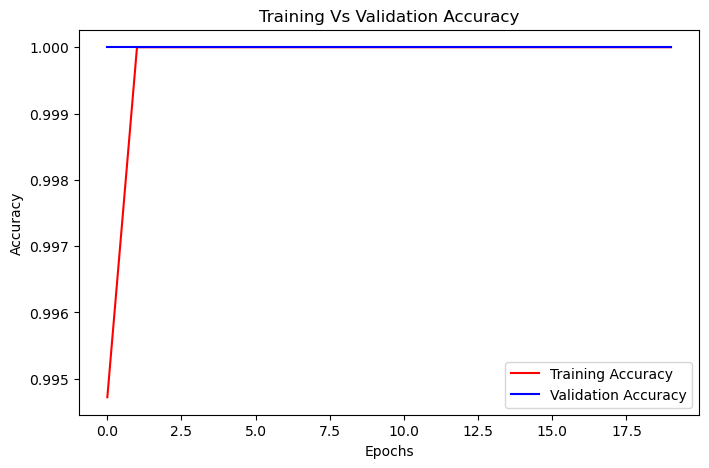

In [91]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='red')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='blue')
plt.title("Training Vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Loss

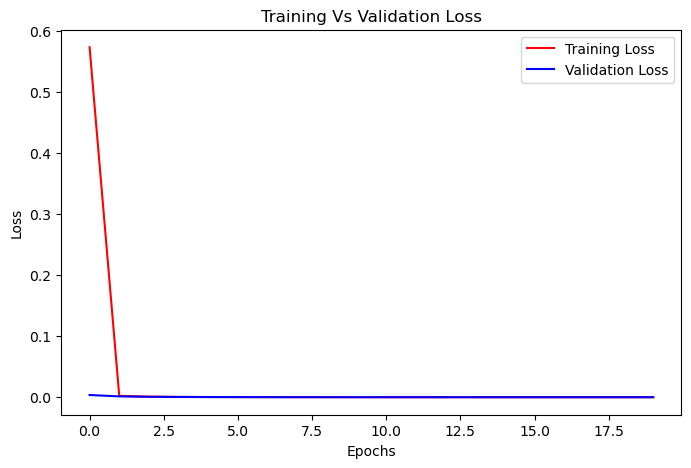

In [92]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss', color='red')
plt.plot(history.history['val_loss'], label='Validation Loss', color='blue')
plt.title("Training Vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### New Sentence Prediction

In [104]:
def translate_sentence(sentence):

    # English → numbers
    encoder_seq = eng_tokenizer.texts_to_sequences([sentence])
    encoder_seq = pad_sequences(encoder_seq, maxlen=encoder_max, padding='pre')

    # Start with <start>
    start_id = urd_tokenizer.word_index['<start>']
    end_id = urd_tokenizer.word_index['<end>']

    decoder_seq = [start_id]

    for i in range(decoder_max - 1):

        decoder_input = pad_sequences(
            [decoder_seq],
            maxlen=decoder_max,
            padding='pre'
        )

        prediction = model.predict(
            [encoder_seq, decoder_input],
            verbose=0
        )

        next_id = np.argmax(prediction[0, i, :])

        if next_id == end_id:
            break

        decoder_seq.append(next_id)

    # Numbers → Urdu words
    words = []

    for id in decoder_seq:
        word = urd_tokenizer.index_word.get(id, '')
        if word not in ['<start>', '<end>', '']:
            words.append(word)

    return ' '.join(words)

In [105]:
sentence = "I am a student."

urdu = translate_sentence(sentence)

print("English:", sentence)
print("Urdu:", urdu)

KeyError: '<start>'

In [101]:
print(translate_sentence("How are you?"))
print(translate_sentence("I love you."))
print(translate_sentence("What is your name?"))
print(translate_sentence("I am learning artificial intelligence."))

اور
اور
اور
اور
